In [1]:
import numpy as np, pandas as pd, joblib
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt, seaborn as sns

X_train = np.load("../data/X_train.npy")
X_test = np.load("../data/X_test.npy")

raw_train = pd.read_csv("../data/KDDTrain.txt", header=None)
raw_test = pd.read_csv("../data/KDDTest.txt", header=None)

family = {"normal": "normal"}
for a in ["back","land","neptune","pod","smurf","teardrop","apache2","udpstorm","processtable","worm","mailbomb"]:
    family[a] = "DoS"
for a in ["ipsweep","nmap","portsweep","satan","mscan","saint"]:
    family[a] = "Probe"
for a in ["ftp_write","guess_passwd","imap","multihop","phf","spy","warezclient","warezmaster",
          "sendmail","named","snmpgetattack","snmpguess","xlock","xsnoop","httptunnel"]:
    family[a] = "R2L"
for a in ["buffer_overflow","loadmodule","perl","rootkit","ps","sqlattack","xterm"]:
    family[a] = "U2R"

y_train = raw_train[41].map(family)
y_test = raw_test[41].map(family)

print("Unmapped labels:", set(raw_train[41][y_train.isna()]) | set(raw_test[41][y_test.isna()]))
print(y_train.value_counts())
print(y_test.value_counts())

Unmapped labels: set()
41
normal    67343
DoS       45927
Probe     11656
R2L         995
U2R          52
Name: count, dtype: int64
41
normal    9711
DoS       7460
R2L       2885
Probe     2421
U2R         67
Name: count, dtype: int64


In [2]:
mc_model = RandomForestClassifier(n_estimators=100, class_weight="balanced",
                                  random_state=42, n_jobs=-1)
mc_model.fit(X_train, y_train)

pred = mc_model.predict(X_test)
print(classification_report(y_test, pred, zero_division=0))

              precision    recall  f1-score   support

         DoS       0.96      0.80      0.87      7460
       Probe       0.86      0.60      0.70      2421
         R2L       0.71      0.00      0.00      2885
         U2R       0.60      0.04      0.08        67
      normal       0.64      0.97      0.78      9711

    accuracy                           0.75     22544
   macro avg       0.76      0.48      0.49     22544
weighted avg       0.78      0.75      0.70     22544



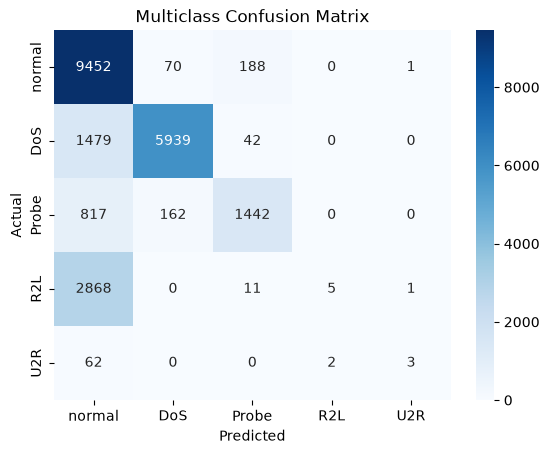

In [3]:
labels = ["normal", "DoS", "Probe", "R2L", "U2R"]
cm = confusion_matrix(y_test, pred, labels=labels)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels)
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("Multiclass Confusion Matrix")
plt.show()

In [4]:
joblib.dump(mc_model, "../data/rf_multiclass.pkl")
print("Saved.")

Saved.
